# Design of the PID in a simplified case
Our actual error function that we want to minimize is a prediction that holds a lot of noise. In this simpler case study I'll just model it as a perfect function that grows linearly with airbrake extension.

The real system will also be subject to more lag between the parameter being tweaked and the results affecting reality and then being captured by the sensors and our Kalman filter.

Another problem is that due to the decreasing velocity our control authority is getting smaller each timestep, so we should have a really good estimate at the start and then just do minor adjustments. 

In [28]:
def heightEstimate(ab_ext: float) -> float:
    assert ab_ext >= 0.0 and ab_ext <= 1.0
    uk_ext = 0.5*ab_ext + 0.01
    h_max = 1000
    h_min = 900
    return h_min + ab_ext*(h_max - h_min)


In [36]:
import numpy as np

TIMESTEP = 0.1 # so 10Hz
TARGET = 960


class Checkpoint:
    ts:float = None
    apogeeEstimate: float = None
    airbrakeExtension: float = None

def uinv(u):
    return u/1000

Kp = 0.9
savestates = []

airbrake = 0.0 # staring position
for t in range(0,10):
    state = heightEstimate(airbrake)
    error = TARGET - state
    print(error)

    airbrake += uinv(error) * Kp

    data = Checkpoint()
    data.ts = t
    data.apogeeEstimate = state
    data.airbrakeExtension = airbrake

    savestates.append(data)



60.0
54.60000000000002
49.686000000000035
45.21425999999997
41.14497659999995
37.441928706
34.07215512246
31.00566116143864
28.215151656909143
25.675788007787332


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[900.0, 905.4, 910.314, 914.78574, 918.8550234, 922.558071294, 925.92784487754, 928.9943388385614, 931.7848483430909, 934.3242119922127]


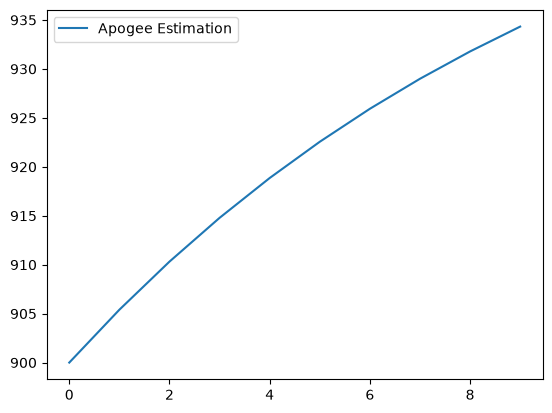

In [38]:
import matplotlib.pyplot as plt

ts = [i.ts for i in savestates]
apgEstimates = [i.apogeeEstimate for i in savestates]
abExt = [i.airbrakeExtension for i in savestates]

print(ts)
print(apgEstimates)

plt.plot(ts,apgEstimates,label="Apogee Estimation")
plt.legend()

plt.show()

In [233]:
class PID:
    error_sum:float = 0.0
    last_error: float = 0.0
    delta_error: float = 0.0

    target: float = 0.0
    Kp:float = 0.0
    Kd:float = 0.0
    Ki:float = 0.0


    def __init__(self, target, Kp, Kd=0.0, Ki=0.0):
        self.target = target
        self.Kp = Kp
        self.Kd = Kd
        self.Ki = Ki
    
    def _error(self,z):
        return self.target-z

    def _clamp_output(self,u):
        return min(max(u,0),1)
            

    def update_with_measurement(self, z,dt):
        err = self._error(z)
        self.error_sum += err*dt
        self.delta_error = (err - self.last_error)/dt

        self.last_error = err

    def get_control_output(self):
        ctrl_out = self.Kp * self.last_error + self.Kd * self.delta_error + self.Ki * self.error_sum
        return self._clamp_output(ctrl_out)


In [296]:
Ku = .010
Tu = 2

TARGET = 950
Kp = 0.6*Ku
pid = PID(target=TARGET, Kp=Kp,Kd=0,Ki=(2*Kp)/Tu)


guesses = []

control = 0.2
for _ in range(100):
    guess = heightEstimate(control)

    pid.update_with_measurement(guess,1)
    u = pid.get_control_output()
    control = u
    guesses.append(guess)


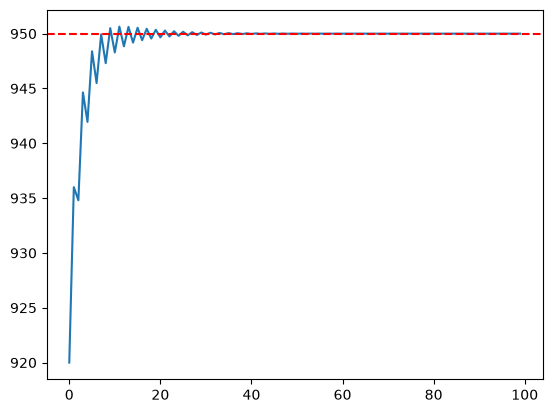

In [297]:
import matplotlib.pyplot as plt

plt.plot(guesses)
plt.axhline(y=TARGET,color="r",linestyle="--")
plt.show()

In [56]:
import constants
import numpy as np
import matplotlib.pyplot as plt

def apogee(v0, CdA, m=constants.ROCKET_BURNOUT_MASS, rho=1.225, g=9.80665, h0=0.0):

    v0, CdA, m = map(np.asarray, (v0, CdA, m))
    k = 0.5 * rho * CdA               # drag constant [kg/m]
    x = k * v0**2 / (m * g)                # dimensionless drag parameter

    # m/(2k) * ln(1+x), with a safe limit as k -> 0 (-> v0^2 / (2g))
    with np.errstate(divide="ignore", invalid="ignore"):
        gain = np.where(k > 0, m / (2.0 * k) * np.log1p(x), v0**2 / (2.0 * g))
    return h0 + gain

class PID:
    def __init__(self, target, kp, ki=0.0, kd=0.0):
        self.target = target
        self.kp, self.ki, self.kd = kp, ki, kd
        self._integral = 0.0
        self._last_measurement = None

        self.min_val, self.max_val = -1,1

    def update(self, z, dt):
        error = self.target - z

        # D on measurement avoids derivative kick
        if self._last_measurement is None:
            derivative = 0.0
        else:
            derivative = -(z - self._last_measurement) / dt
        self._last_measurement = z

        p = self.kp * error
        d = self.kd * derivative

        new_integral = self._integral + error * dt
        u = p + self.ki * new_integral + d
        if self.min_val < u < self.max_val:
            self._integral = new_integral

        # clamping value between 0 and 1 for airbrake
        return min(max(u, self.min_val), self.max_val)

def clamp(u):
    return max(min(u,1),0)


## Model simplification

We need a much simpler model of the actual simulation to get a good PI(D) tuning going. As the system is time-variant we want to apply the inverse to make it seem time invariant to the PID system. A constant timestep euler approximation should be fine were we also have $v$ as a state to cancel out the quadratic control authority relationship.

A singular function that spits out the development of our target depending on the inputs as $K_p$ and $K_i$ would be desireable.

In [ ]:
TIMESTEP = 0.1 #s
TARGET = 970 #m
V0 = 130 # m/s
H0 = 250 # m


def simpleSimulation(u0, kp, ki, kd, t0=3, tf=17):
    pid = PID(TARGET,kp=kp, ki=ki, kd=kd)

    ## Logging
    ts_ = []
    hs_ = []
    vs_ = []
    us_ = []
    hes_ = []

    v = V0
    h = H0
    u = u0
    for t in np.arange(t0,tf,TIMESTEP):
        if h <= 0:
            break

        ## Update the system state
        A_total = 3 * constants.AIRBRAKE_FLAP_HEIGHT * constants.AIRBRAKE_FLAP_WIDTH
        cda_total = u*A_total * constants.ROCKET_AIRBRAKE_DEFAULT_CD + constants.ROCKET_CSA * constants.ROCKET_DEFAULT_CD
        drag = 0.5 * 1.225 * (cda_total) * v**2
        h += v*TIMESTEP
        v += (-9.81 - drag/constants.ROCKET_BURNOUT_MASS)*TIMESTEP

        ## Make "measurement" for pid
        z = apogee(v,cda_total, h0=h)

        ## Do PI(D) action
        du = pid.update(z,TIMESTEP)
        u -= du
        u = clamp(u)

        ## Logging data
        ts_.append(t)
        hs_.append(h)
        vs_.append(v)
        us_.append(u)
        hes_.append(z)

    return ts_,hs_,vs_,us_,hes_

Apogee: 972.76 m


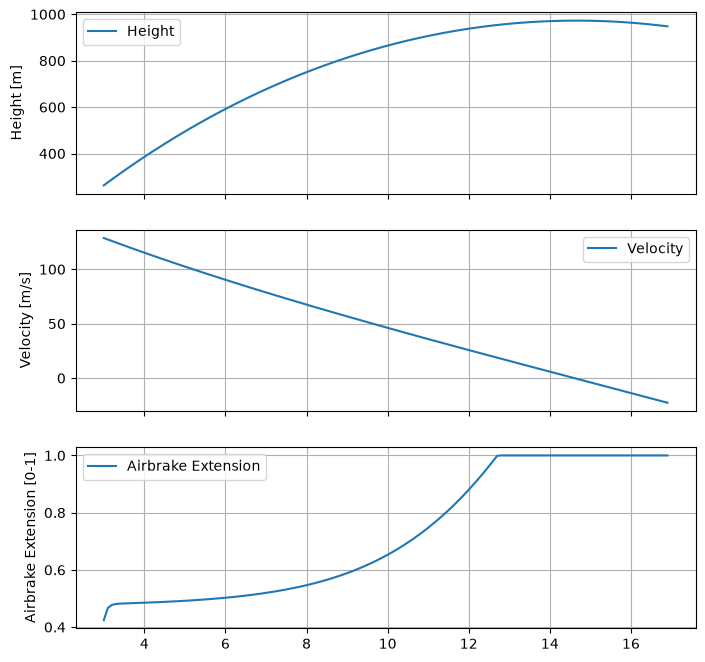

In [ ]:

ts_,hs_,vs_,us_,hes_ = simpleSimulation(u0=0.2,kp=0.01,ki=0,kd=0)

print(f"Apogee: {max(hs_):.2f} m")

# Plot all the results
fig, ax = plt.subplots(3,1,sharex=True,figsize=(8,8))
ax[0].plot(ts_,hs_,label="Height")
ax[0].set_ylabel("Height [m]")
ax[0].grid(True)
ax[0].legend()

ax[1].plot(ts_,vs_,label="Velocity")
ax[1].set_ylabel("Velocity [m/s]")
ax[1].grid(True)
ax[1].legend()

ax[2].plot(ts_,us_,label="Airbrake Extension")
ax[2].set_ylabel("Airbrake Extension [0-1]")
ax[2].grid(True)
ax[2].legend()


plt.grid(True)
plt.show()